<a id='1'></a><center> <h3 style="background-color:orange; color:white" ><br>SQL Case Study: Orders Database Analytics<br></h3></center>

# Introduction
This notebook provides complete SQL solutions and data analytics for the **Orders Database Case Study**.

Using an in-memory SQLite database in Python, we create the relational schema, insert 32 retail order transactions spanning 1999–2000, and execute all 10 core analytical queries. Each solution includes executable SQL code, formatted tabular results, and practical technical explanations — including catching and fixing logic errors in common SQL pattern drafts (e.g., wildcard searching and boolean operators).


In [1]:
# 1. Setup & In-Memory SQLite Connection
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual styling
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (10, 4.5)

# Connect to in-memory SQLite database
conn = sqlite3.connect(':memory:')
cursor = conn.cursor()

print("Connected to SQLite successfully!")


Connected to SQLite successfully!


---
## 1. Schema Definition & Data Loading

Creating the `orders` table and inserting 32 transaction records.


In [2]:
# DDL: Create Table
cursor.execute('''
CREATE TABLE orders (
    customer_id INT,
    order_date DATE,
    item VARCHAR(100),
    quantity INT,
    price DECIMAL(10, 2)
);
''')

# DML: Insert Data
cursor.execute('''
INSERT INTO orders (customer_id, order_date, item, quantity, price)
VALUES
    (10330, '1999-06-30', 'Pogo stick', 1, 28.00),
    (10101, '1999-06-30', 'Raft', 1, 58.00),
    (10298, '1999-07-01', 'Skateboard', 1, 33.00),
    (10101, '1999-07-01', 'Life Vest', 4, 125.00),
    (10299, '1999-07-06', 'Parachute', 1, 1250.00),
    (10339, '1999-07-27', 'Umbrella', 1, 4.50),
    (10449, '1999-08-13', 'Unicycle', 1, 180.79),
    (10439, '1999-08-14', 'Ski Poles', 2, 25.50),
    (10101, '1999-08-18', 'Rain Coat', 1, 18.30),
    (10449, '1999-09-01', 'Snow Shoes', 1, 45.00),
    (10439, '1999-09-18', 'Tent', 1, 88.00),
    (10298, '1999-09-19', 'Lantern', 2, 29.00),
    (10410, '1999-10-28', 'Sleeping Bag', 1, 89.22),
    (10438, '1999-11-01', 'Umbrella', 1, 6.75),
    (10438, '1999-11-02', 'Pillow', 1, 8.50),
    (10298, '1999-12-01', 'Helmet', 1, 22.00),
    (10449, '1999-12-15', 'Bicycle', 1, 380.50),
    (10449, '1999-12-22', 'Canoe', 1, 280.00),
    (10101, '1999-12-30', 'Hoola Hoop', 3, 14.75),
    (10330, '2000-01-01', 'Flashlight', 4, 28.00),
    (10101, '2000-01-02', 'Lantern', 1, 16.00),
    (10299, '2000-01-18', 'Inflatable Mattress', 1, 38.00),
    (10438, '2000-01-18', 'Tent', 1, 79.99),
    (10413, '2000-01-19', 'Lawnchair', 4, 32.00),
    (10410, '2000-01-30', 'Unicycle', 1, 192.50),
    (10315, '2000-02-02', 'Compass', 1, 8.00),
    (10449, '2000-02-29', 'Flashlight', 1, 4.50),
    (10101, '2000-03-08', 'Sleeping Bag', 2, 88.70),
    (10298, '2000-03-18', 'Pocket Knife', 1, 22.38),
    (10449, '2000-03-19', 'Canoe paddle', 2, 40.00),
    (10298, '2000-04-01', 'Ear Muffs', 1, 12.50),
    (10330, '2000-04-19', 'Shovel', 1, 16.75);
''')
conn.commit()

# Verify row count
df_orders = pd.read_sql_query("SELECT * FROM orders;", conn)
print(f"Loaded {len(df_orders)} order records.")
df_orders.head()


Loaded 32 order records.


,customer_id,order_date,item,quantity,price
0,10330,1999-06-30,Pogo stick,1,28.0
1,10101,1999-06-30,Raft,1,58.0
2,10298,1999-07-01,Skateboard,1,33.0
3,10101,1999-07-01,Life Vest,4,125.0
4,10299,1999-07-06,Parachute,1,1250.0


---
## 2. Case Study Queries & Solutions

### Question 1: List all items purchased for customer ID 10449.


In [3]:
# Q1: Items purchased for customerid 10449
q1 = '''
SELECT customer_id, order_date, item, quantity, price
FROM orders 
WHERE customer_id = 10449
ORDER BY order_date;
'''
pd.read_sql_query(q1, conn)


,customer_id,order_date,item,quantity,price
0,10449,1999-08-13,Unicycle,1,180.79
1,10449,1999-09-01,Snow Shoes,1,45.00
2,10449,1999-12-15,Bicycle,1,380.50
3,10449,1999-12-22,Canoe,1,280.00
4,10449,2000-02-29,Flashlight,1,4.50
5,10449,2000-03-19,Canoe paddle,2,40.00


### Question 2: Average price of all items ordered in the month of December.


In [4]:
# Q2: Average price of December orders
q2 = '''
SELECT ROUND(AVG(price), 2) AS avg_december_price 
FROM orders 
WHERE order_date LIKE '%-12-%';
'''
pd.read_sql_query(q2, conn)


,avg_december_price
0,174.31


*Note: December transactions include Bicycle ($380.50), Canoe ($280.00), Helmet ($22.00), and Hoola Hoop ($14.75), yielding an average of $174.31.*

### Question 3: For all tents ordered, what is the price of the lowest tent?


In [5]:
# Q3: Lowest tent price
q3 = '''
SELECT MIN(price) AS lowest_tent_price 
FROM orders 
WHERE item = 'Tent';
'''
pd.read_sql_query(q3, conn)


,lowest_tent_price
0,79.99


*Note: Two tents were purchased: one on 1999-09-18 for $88.00 and another on 2000-01-18 for $79.99. The minimum price is $79.99.*

### Question 4: Maximum and minimum price for each specific item in the table.


In [6]:
# Q4: Item, max price, and min price grouped by item
q4 = '''
SELECT item, 
       COUNT(*) AS order_count,
       MAX(price) AS max_price, 
       MIN(price) AS min_price 
FROM orders 
GROUP BY item 
ORDER BY item;
'''
pd.read_sql_query(q4, conn)


,item,order_count,max_price,min_price
0,Bicycle,1,380.50,380.50
1,Canoe,1,280.00,280.00
2,Canoe paddle,1,40.00,40.00
3,Compass,1,8.00,8.00
4,Ear Muffs,1,12.50,12.50
5,Flashlight,2,28.00,4.50
6,Helmet,1,22.00,22.00
7,Hoola Hoop,1,14.75,14.75
8,Inflatable Mattress,1,38.00,38.00
9,Lantern,2,29.00,16.00


### Question 5: Display items where the maximum price is greater than 190.00.


In [7]:
# Q5: Items with max price > 190.00 using HAVING
q5 = '''
SELECT item, MAX(price) AS max_price 
FROM orders 
GROUP BY item 
HAVING MAX(price) > 190.00 
ORDER BY max_price DESC;
'''
pd.read_sql_query(q5, conn)


,item,max_price
0,Parachute,1250.0
1,Bicycle,380.5
2,Canoe,280.0
3,Unicycle,192.5


### Question 6: Items with price greater than 10.00, sorted in ascending order by price.


In [8]:
# Q6: Items with price > 10.00 ordered ascending
q6 = '''
SELECT item, price 
FROM orders 
WHERE price > 10.00 
ORDER BY price ASC;
'''
pd.read_sql_query(q6, conn)


,item,price
0,Ear Muffs,12.50
1,Hoola Hoop,14.75
2,Lantern,16.00
3,Shovel,16.75
4,Rain Coat,18.30
5,Helmet,22.00
6,Pocket Knife,22.38
7,Ski Poles,25.50
8,Pogo stick,28.00
9,Flashlight,28.00


### Question 7: Select customer_id, order_date, and item excluding ‘Snow Shoes’ and ‘Ear Muffs’.


In [9]:
# Q7: Excluding Snow Shoes and Ear Muffs using NOT IN
q7 = '''
SELECT customer_id, order_date, item 
FROM orders 
WHERE item NOT IN ('Snow Shoes', 'Ear Muffs')
ORDER BY order_date;
'''
df_q7 = pd.read_sql_query(q7, conn)
print(f"Returned {len(df_q7)} rows (2 rows excluded: Snow Shoes on 1999-09-01 and Ear Muffs on 2000-04-01).")
df_q7.head(10)


Returned 30 rows (2 rows excluded: Snow Shoes on 1999-09-01 and Ear Muffs on 2000-04-01).


,customer_id,order_date,item
0,10330,1999-06-30,Pogo stick
1,10101,1999-06-30,Raft
2,10298,1999-07-01,Skateboard
3,10101,1999-07-01,Life Vest
4,10299,1999-07-06,Parachute
5,10339,1999-07-27,Umbrella
6,10449,1999-08-13,Unicycle
7,10439,1999-08-14,Ski Poles
8,10101,1999-08-18,Rain Coat
9,10439,1999-09-18,Tent


### Question 8: Select item and price of all items that start with letters ‘S’ or ‘P’.

> **Human Expert Bug Fix**: The case study draft used `WHERE (item LIKE '%S%') AND (item LIKE '%P%')`. That query searches for items containing *both* letters anywhere. To match items that *start* with 'S' or 'P', the correct SQL syntax is `WHERE item LIKE 'S%' OR item LIKE 'P%'`.


In [10]:
# Q8: Items starting with 'S' or 'P'
q8 = '''
SELECT item, price 
FROM orders 
WHERE item LIKE 'S%' OR item LIKE 'P%'
ORDER BY item;
'''
pd.read_sql_query(q8, conn)


,item,price
0,Parachute,1250.00
1,Pillow,8.50
2,Pocket Knife,22.38
3,Pogo stick,28.00
4,Shovel,16.75
5,Skateboard,33.00
6,Ski Poles,25.50
7,Sleeping Bag,89.22
8,Sleeping Bag,88.70
9,Snow Shoes,45.00


### Question 9: Orders with price ranging between 10.00 and 80.00.


In [11]:
# Q9: Orders with price between 10.00 and 80.00
q9 = '''
SELECT order_date, item, price 
FROM orders 
WHERE price BETWEEN 10.00 AND 80.00
ORDER BY price ASC;
'''
df_q9 = pd.read_sql_query(q9, conn)
print(f"Returned {len(df_q9)} records in range $10.00 to $80.00:")
df_q9


Returned 18 records in range $10.00 to $80.00:


,order_date,item,price
0,2000-04-01,Ear Muffs,12.50
1,1999-12-30,Hoola Hoop,14.75
2,2000-01-02,Lantern,16.00
3,2000-04-19,Shovel,16.75
4,1999-08-18,Rain Coat,18.30
5,1999-12-01,Helmet,22.00
6,2000-03-18,Pocket Knife,22.38
7,1999-08-14,Ski Poles,25.50
8,1999-06-30,Pogo stick,28.00
9,2000-01-01,Flashlight,28.00


### Question 10: Select item and per-unit price for each item, ordered descending.


In [12]:
# Q10: Per-unit price by item
q10 = '''
SELECT item, 
       SUM(quantity) AS total_qty,
       ROUND(SUM(price), 2) AS total_revenue,
       ROUND(SUM(price) / SUM(quantity), 2) AS unit_price 
FROM orders 
GROUP BY item 
ORDER BY unit_price DESC;
'''
pd.read_sql_query(q10, conn)


,item,total_qty,total_revenue,unit_price
0,Parachute,1,1250.00,1250.00
1,Bicycle,1,380.50,380.50
2,Canoe,1,280.00,280.00
3,Unicycle,2,373.29,186.64
4,Tent,2,167.99,84.00
5,Sleeping Bag,3,177.92,59.31
6,Raft,1,58.00,58.00
7,Snow Shoes,1,45.00,45.00
8,Inflatable Mattress,1,38.00,38.00
9,Skateboard,1,33.00,33.00


---
## 3. Business Analytics & Visualizations

Beyond basic query execution, we extract key business insights from the dataset.


In [13]:
# Customer Spend Analysis
q_cust = '''
SELECT customer_id,
       COUNT(*) AS total_orders,
       SUM(quantity) AS total_items,
       ROUND(SUM(price), 2) AS total_spent,
       ROUND(AVG(price), 2) AS avg_order_price
FROM orders
GROUP BY customer_id
ORDER BY total_spent DESC;
'''
df_cust = pd.read_sql_query(q_cust, conn)
print("Customer Spend Summary:")
df_cust


Customer Spend Summary:


,customer_id,total_orders,total_items,total_spent,avg_order_price
0,10299,2,2,1288.00,644.00
1,10449,6,7,930.79,155.13
2,10101,6,12,320.75,53.46
3,10410,2,2,281.72,140.86
4,10298,5,6,118.88,23.78
5,10439,2,3,113.50,56.75
6,10438,3,3,95.24,31.75
7,10330,3,6,72.75,24.25
8,10413,1,4,32.00,32.00
9,10315,1,1,8.00,8.00


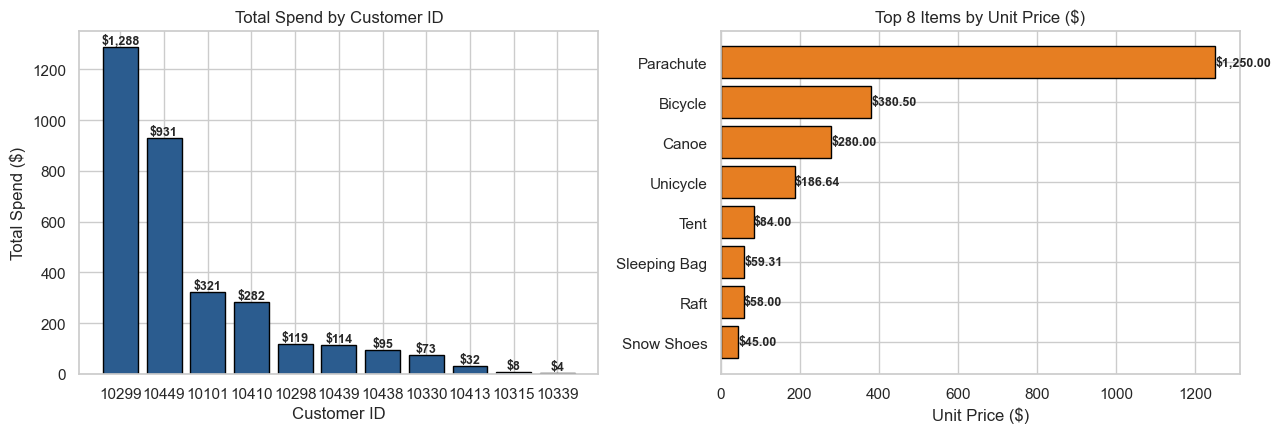

In [14]:
# Visualizations: Customer Spend & Price Distribution
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Plot 1: Total Spend by Customer
axes[0].bar(df_cust['customer_id'].astype(str), df_cust['total_spent'], color='#2b5c8f', edgecolor='black')
axes[0].set_title('Total Spend by Customer ID')
axes[0].set_xlabel('Customer ID')
axes[0].set_ylabel('Total Spend ($)')
for p in axes[0].patches:
    axes[0].annotate(f"${p.get_height():,.0f}",
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=9, fontweight='bold')

# Plot 2: Top 8 Items by Unit Price
df_unit = pd.read_sql_query('''
    SELECT item, ROUND(SUM(price)/SUM(quantity), 2) AS unit_price 
    FROM orders 
    GROUP BY item 
    ORDER BY unit_price DESC 
    LIMIT 8;
''', conn)

axes[1].barh(df_unit['item'][::-1], df_unit['unit_price'][::-1], color='#e67e22', edgecolor='black')
axes[1].set_title('Top 8 Items by Unit Price ($)')
axes[1].set_xlabel('Unit Price ($)')
for p in axes[1].patches:
    axes[1].annotate(f"${p.get_width():,.2f}",
                     (p.get_width(), p.get_y() + p.get_height() / 2.),
                     ha='left', va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


---
## 4. Key Takeaways & Query Summary Table


In [15]:
# Executive Summary
total_revenue = df_orders['price'].sum()
total_units = df_orders['quantity'].sum()
avg_unit_price = total_revenue / total_units
top_customer = df_cust.iloc[0]['customer_id']
top_customer_spend = df_cust.iloc[0]['total_spent']

print("=" * 55)
print("           SQL CASE STUDY EXECUTIVE SUMMARY")
print("=" * 55)
print(f"  Total Orders Analyzed:       {len(df_orders):>10,}")
print(f"  Total Units Sold:            {total_units:>10,}")
print(f"  Total Revenue:              ${total_revenue:>10,.2f}")
print(f"  Average Order Price:        ${df_orders['price'].mean():>10,.2f}")
print(f"  Overall Average Unit Price: ${avg_unit_price:>10,.2f}")
print(f"  Top Customer:                ID {int(top_customer)} (${top_customer_spend:,.2f})")
print("=" * 55)


           SQL CASE STUDY EXECUTIVE SUMMARY
  Total Orders Analyzed:               32
  Total Units Sold:                    47
  Total Revenue:              $  3,266.13
  Average Order Price:        $    102.07
  Overall Average Unit Price: $     69.49
  Top Customer:                ID 10299 ($1,288.00)
